<a href="https://colab.research.google.com/github/MuminjonPI/shark-app/blob/main/notebook/train.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🦈 Shark vs Phones — training notebook

**ML Project 1** · Muminjon Khayitboev · November 2026

This notebook trains a **phone detector** for a webcam game where a shark "eats" any phone held up to the camera.

**Pipeline**

1. Download phone images from COCO 2017 with FiftyOne
2. Fine-tune **YOLO26n** (Ultralytics) on a Colab T4 GPU
3. Test the trained model on a new photo
4. Upload the weights to Hugging Face
5. Export to **ONNX** so the model can run in a web browser

**Links**

- Model: https://huggingface.co/MuminjonPI/shark-phone-detector
- Gradio demo: https://huggingface.co/spaces/MuminjonPI/shark-app
- Code and report: https://github.com/MuminjonPI/shark-app

> **Before running:** Runtime → Change runtime type → **T4 GPU**.

## 1. Setup

Install **Ultralytics** (YOLO training) and **FiftyOne** (dataset download and conversion).

A pip warning about `gradio` and `pillow` may appear. It can be ignored, because Gradio is not used in this notebook.

In [ ]:
!pip install -q ultralytics fiftyone

## 2. Download the dataset

COCO 2017 already contains a `cell phone` class, so no manual labelling is needed.
FiftyOne downloads only images that contain a phone:

| Split | Images |
|---|---|
| train | 500 |
| validation | 100 |

`label_types=["detections"]` means bounding boxes are loaded.

In [ ]:
import fiftyone as fo
import fiftyone.zoo as foz
from fiftyone import ViewField as F

train = foz.load_zoo_dataset(
    "coco-2017",
    split="train",
    label_types=["detections"],
    classes=["cell phone"],
    max_samples=500,
)
val = foz.load_zoo_dataset(
    "coco-2017",
    split="validation",
    label_types=["detections"],
    classes=["cell phone"],
    max_samples=100,
)

print(len(train), len(val))

INFO:fiftyone.zoo.datasets:Downloading split 'train' to '/root/fiftyone/coco-2017/train' if necessary


Found annotations at '/root/fiftyone/coco-2017/raw/instances_train2017.json'


INFO:fiftyone.utils.coco:Found annotations at '/root/fiftyone/coco-2017/raw/instances_train2017.json'


Sufficient images already downloaded


INFO:fiftyone.utils.coco:Sufficient images already downloaded


Existing download of split 'train' is sufficient


... (9 outputs left out)

INFO:fiftyone.zoo.datasets:Existing download of split 'validation' is sufficient


Loading existing dataset 'coco-2017-validation-100'. To reload from disk, either delete the existing dataset or provide a custom `dataset_name` to use


INFO:fiftyone.zoo.datasets:Loading existing dataset 'coco-2017-validation-100'. To reload from disk, either delete the existing dataset or provide a custom `dataset_name` to use


500 100


## 3. Keep only phone labels and export in YOLO format

COCO images also contain other objects (people, cups, laptops). `filter_labels` keeps only the `cell phone` boxes,
then both splits are exported into one folder in the YOLO format that Ultralytics expects (`images/`, `labels/`, `dataset.yaml`).

The "directory already exists, export will be merged" warning is expected: the validation split is written into the same folder as the training split.

In [ ]:
for ds, split in [(train, "train"), (val, "val")]:
    view = ds.filter_labels("ground_truth", F("label")== "cell phone")
    view.export(
        export_dir = "/content/phones",
        dataset_type=fo.types.YOLOv5Dataset,
        label_field = "ground_truth",
        split=split,
        classes=["cell phone"],
    )

Directory '/content/phones' already exists; export will be merged with existing files


Directory '/content/phones/images/train' already exists; export will be merged with existing files


Directory '/content/phones/labels/train' already exists; export will be merged with existing files


 100% |█████████████████| 500/500 [1.3s elapsed, 0s remaining, 384.6 samples/s]         


INFO:eta.core.utils: 100% |█████████████████| 500/500 [1.3s elapsed, 0s remaining, 384.6 samples/s]         


Directory '/content/phones' already exists; export will be merged with existing files


Directory '/content/phones/images/val' already exists; export will be merged with existing files


Directory '/content/phones/labels/val' already exists; export will be merged with existing files


 100% |█████████████████| 100/100 [257.8ms elapsed, 0s remaining, 387.9 samples/s]      


INFO:eta.core.utils: 100% |█████████████████| 100/100 [257.8ms elapsed, 0s remaining, 387.9 samples/s]      


### Check the exported dataset

`dataset.yaml` should list one class (`0: cell phone`) and the `train` / `val` image folders.

In [ ]:
!ls /content/phones
!cat /content/phones/dataset.yaml

dataset.yaml  images  labels
names:
  0: cell phone
path: /content/phones
train: ./images/train/
val: ./images/val/


## 4. Train YOLO26n

Fine-tune the small pretrained **YOLO26n** model (about 2.5 million parameters) on the phone dataset.
Starting from COCO-pretrained weights lets training take only a few minutes.

| Setting | Value | Why |
|---|---|---|
| `epochs` | 20 | short run that fits the time budget |
| `imgsz` | 640 | standard YOLO input size |
| `batch` | 8 | the first run with batch 16 crashed the Colab session (most likely out of RAM) |
| `workers` | 0 | no extra data-loading processes, to save memory |

**Result** (validation, best checkpoint): Precision 0.550 · Recall 0.366 · **mAP50 0.414** · mAP50-95 0.238.
Training took about 5.5 minutes on a Tesla T4.

The weights are saved in `runs/detect/shark_phone-5/weights/best.pt`. The `-5` suffix appears because earlier attempts created `shark_phone`, `shark_phone-2`, and so on.

In [ ]:
from ultralytics import YOLO

model = YOLO("yolo26n.pt")
results = model.train(
    data="/content/phones/dataset.yaml",
    epochs=20,
    imgsz=640,
    batch=8,
    workers=0,
    name="shark_phone",
)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/phones/dataset.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=shark_phone-5, nbs=64, nms=None, opset=None, optimize=False, 

## 5. Test on a new photo

Run the trained model on an image it has never seen. `conf=0.25` keeps only boxes with a phone score of at least 25%.

Result: one phone detected with **0.80 confidence** and no false detections.


image 1/1 /content/manphone.jpeg: 448x640 1 cell phone, 64.2ms
Speed: 14.1ms preprocess, 64.2ms inference, 10.3ms postprocess per image at shape (1, 3, 448, 640)


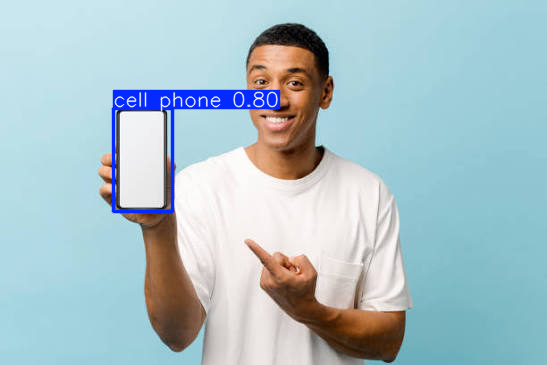

In [ ]:
from ultralytics import YOLO

best = YOLO("/content/runs/detect/shark_phone-5/weights/best.pt")
res = best.predict("/content/manphone.jpeg", conf=0.25)
res[0].show()

## 6. Upload the model to Hugging Face

### 6.1 Log in

`notebook_login()` opens a Hugging Face login. Approve the request in the browser (check that the device code matches).
No password or token is written into the notebook.

In [ ]:
from huggingface_hub import notebook_login
notebook_login()

### 6.2 Create the model repo and upload `best.pt`

`create_repo(..., exist_ok=True)` creates `MuminjonPI/shark-phone-detector` (or does nothing if it already exists), and `upload_file` sends the PyTorch weights.

In [ ]:
from huggingface_hub import HfApi

api = HfApi()
repo_id = "MuminjonPI/shark-phone-detector"

api.create_repo(repo_id, repo_type="model", exist_ok=True)
api.upload_file(
    path_or_fileobj="/content/runs/detect/shark_phone-5/weights/best.pt",
    path_in_repo="best.pt",
    repo_id=repo_id,
)

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...k_phone-5/weights/best.pt:  10%|9         |  542kB / 5.43MB            

Validating                    :           |   0%            

CommitInfo(commit_url='https://huggingface.co/MuminjonPI/shark-phone-detector/commit/ba7d5f86639875e50e26212bc70fa0dea400639c', commit_message='Upload best.pt with huggingface_hub', commit_description='', oid='ba7d5f86639875e50e26212bc70fa0dea400639c', pr_url=None, repo_url=RepoUrl('https://huggingface.co/MuminjonPI/shark-phone-detector', endpoint='https://huggingface.co', repo_type='model', repo_id='MuminjonPI/shark-phone-detector'), pr_revision=None, pr_num=None)

### 6.3 Re-run the upload (check)

Running the upload again shows *"No files have been modified since last commit"*, which confirms that `best.pt` is already on Hugging Face.

In [ ]:
from huggingface_hub import HfApi

api = HfApi()
api.upload_file(
    path_or_fileobj="/content/runs/detect/shark_phone-5/weights/best.pt",
    path_in_repo="best.pt",
    repo_id="MuminjonPI/shark-phone-detector",
)

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...k_phone-5/weights/best.pt: 100%|##########| 5.43MB / 5.43MB            

Validating                    :           |   0%            

No files have been modified since last commit. Skipping to prevent empty commit.


CommitInfo(commit_url='https://huggingface.co/MuminjonPI/shark-phone-detector/commit/ba7d5f86639875e50e26212bc70fa0dea400639c', commit_message='Upload best.pt with huggingface_hub', commit_description='', oid='ba7d5f86639875e50e26212bc70fa0dea400639c', pr_url=None, repo_url=RepoUrl('https://huggingface.co/MuminjonPI/shark-phone-detector', endpoint='https://huggingface.co', repo_type='model', repo_id='MuminjonPI/shark-phone-detector'), pr_revision=None, pr_num=None)

## 7. Export to ONNX for the web app

The Vercel web app runs the model **inside the browser** with ONNX Runtime Web, so the webcam image never leaves the user's device.
For that, the PyTorch weights are converted to **ONNX** (9.4 MB).

In [ ]:
from ultralytics import YOLO
best = YOLO("/content/runs/detect/shark_phone-5/weights/best.pt")
onnx_path = best.export(format="onnx", imgsz=640)
print(onnx_path)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO26n summary (fused): 121 layers, 2,389,735 parameters, 0 gradients, 5.4 GFLOPs

PyTorch: starting from '/content/runs/detect/shark_phone-5/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 5, 8400) (5.2 MB)
requirements: Ultralytics requirements ['onnx>=1.12.0,<2.0.0', 'onnxruntime', 'onnxslim>=0.1.82'] not found, attempting AutoUpdate...
Using Python 3.13.16 environment at: /usr
Resolved 12 packages in 567ms
Prepared 4 packages in 1.06s
Installed 4 packages in 53ms
 + colorama==0.4.6
 + onnx==1.23.2
 + onnxruntime==1.32.0
 + onnxslim==0.1.99

requirements: AutoUpdate success ✅ 2.2s
WARNING ⚠️ requirements: Restart runtime or rerun command for updates to take effect


ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: slim

### 7.1 Upload `best.onnx` to Hugging Face

The web app downloads the model directly from this repo:
`https://huggingface.co/MuminjonPI/shark-phone-detector/resolve/main/best.onnx`

In [ ]:
from huggingface_hub import HfApi

api = HfApi()
api.upload_file(
    path_or_fileobj=onnx_path,          # the variable from Cell 1
    path_in_repo="best.onnx",           # the name on Hugging Face
    repo_id="MuminjonPI/shark-phone-detector",
)

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...phone-5/weights/best.onnx:   6%|5         |  558kB / 9.85MB            

Validating                    :           |   0%            

CommitInfo(commit_url='https://huggingface.co/MuminjonPI/shark-phone-detector/commit/e6c79e542cd9bba214b57473d82c40bdbc9cea3e', commit_message='Upload best.onnx with huggingface_hub', commit_description='', oid='e6c79e542cd9bba214b57473d82c40bdbc9cea3e', pr_url=None, repo_url=RepoUrl('https://huggingface.co/MuminjonPI/shark-phone-detector', endpoint='https://huggingface.co', repo_type='model', repo_id='MuminjonPI/shark-phone-detector'), pr_revision=None, pr_num=None)

### 7.2 Inspect the ONNX model

The web app needs the exact input and output names and shapes:

| | Name | Shape | Meaning |
|---|---|---|---|
| Input | `images` | `[1, 3, 640, 640]` | one RGB image, 640 × 640, values 0–1 |
| Output | `output0` | `[1, 5, 8400]` | 8,400 candidate boxes × (centre x, centre y, width, height, phone score) |

Overlapping boxes are not removed inside this model, so the web app applies **non-maximum suppression (NMS)** in JavaScript.

In [ ]:
!pip install -q onnxruntime
import onnxruntime as ort
s = ort.InferenceSession(onnx_path)
print([(i.name, i.shape) for i in s.get_inputs()])
print([(o.name, o.shape) for o in s.get_outputs()])

[('images', [1, 3, 640, 640])]
[('output0', [1, 5, 8400])]


## 8. Summary

| Step | Output |
|---|---|
| Data | 500 train + 100 val COCO `cell phone` images |
| Training | YOLO26n, 20 epochs, about 5.5 min on a T4 |
| Validation | Precision 0.550 · Recall 0.366 · mAP50 0.414 · mAP50-95 0.238 |
| Weights | `best.pt` and `best.onnx` on [Hugging Face](https://huggingface.co/MuminjonPI/shark-phone-detector) |
| Apps | Vercel web app (in-browser, private) and [Hugging Face Space](https://huggingface.co/spaces/MuminjonPI/shark-app) |

**Next steps:** train longer (50+ epochs), add my own webcam photos to the dataset, and add head tracking so the player steers the shark.